In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

np.random.seed(42)



In [2]:
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/00267/data_banknote_authentication.txt"
)

columns = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

df = pd.read_csv(url, header=None, names=columns)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully.
Dataset shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [3]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["class"].value_counts().sort_index())

print("\nStatistical summary:")
display(df.describe())


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Class distribution:
class
0    762
1    610
Name: count, dtype: int64

Statistical summary:


,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


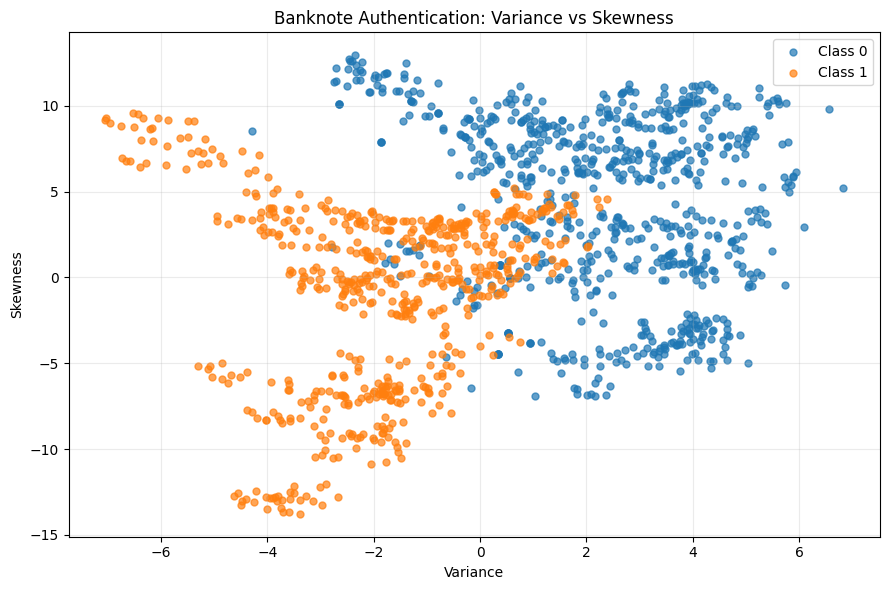

In [4]:
plt.figure(figsize=(9, 6))

for label in sorted(df["class"].unique()):
    subset = df[df["class"] == label]

    plt.scatter(
        subset["variance"],
        subset["skewness"],
        label=f"Class {label}",
        alpha=0.7,
        s=25
    )

plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Banknote Authentication: Variance vs Skewness")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [5]:
# All four features for final evaluation
X = df[["variance", "skewness", "curtosis", "entropy"]].to_numpy()
y = df["class"].to_numpy()

# Two features for decision-boundary plots
X_2d = df[["variance", "skewness"]].to_numpy()

print("Full feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Two-feature matrix shape:", X_2d.shape)


Full feature matrix shape: (1372, 4)
Target shape: (1372,)
Two-feature matrix shape: (1372, 2)


In [6]:
# Split all four features
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split the two-feature data using the same indices
indices = np.arange(len(y))

train_indices, test_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train_2d = X_2d[train_indices]
X_test_2d = X_2d[test_indices]

print("Four-feature training set:", X_train.shape)
print("Four-feature testing set:", X_test.shape)
print("Two-feature training set:", X_train_2d.shape)
print("Two-feature testing set:", X_test_2d.shape)
print("Training class counts:", np.bincount(y_train))
print("Testing class counts:", np.bincount(y_test))

Four-feature training set: (1097, 4)
Four-feature testing set: (275, 4)
Two-feature training set: (1097, 2)
Two-feature testing set: (275, 2)
Training class counts: [609 488]
Testing class counts: [153 122]


In [7]:
def gini_impurity(y):
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1.0 - np.sum(probabilities ** 2)


def entropy(y):
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return -np.sum(
        probabilities * np.log2(probabilities)
    )


# Verify both functions
test_labels = np.array([0, 0, 1, 1])

print("Gini for balanced labels:", gini_impurity(test_labels))
print("Entropy for balanced labels:", entropy(test_labels))

pure_labels = np.array([1, 1, 1, 1])

print("Gini for pure labels:", gini_impurity(pure_labels))
print("Entropy for pure labels:", entropy(pure_labels))


Gini for balanced labels: 0.5
Entropy for balanced labels: 1.0
Gini for pure labels: 0.0
Entropy for pure labels: -0.0


In [8]:
def best_split(X, y, criterion="gini"):
    n_samples, n_features = X.shape

    if n_samples < 2:
        return None, None, None

    if criterion == "gini":
        impurity_function = gini_impurity
    elif criterion == "entropy":
        impurity_function = entropy
    else:
        raise ValueError("Criterion must be 'gini' or 'entropy'.")

    parent_impurity = impurity_function(y)

    best_gain = 0.0
    best_feature = None
    best_threshold = None

    for feature_index in range(n_features):
        values = np.unique(X[:, feature_index])

        # Midpoints between consecutive unique values
        thresholds = (values[:-1] + values[1:]) / 2.0

        for threshold in thresholds:
            left_mask = X[:, feature_index] <= threshold
            right_mask = ~left_mask

            y_left = y[left_mask]
            y_right = y[right_mask]

            if len(y_left) == 0 or len(y_right) == 0:
                continue

            weighted_impurity = (
                len(y_left) / n_samples * impurity_function(y_left)
                + len(y_right) / n_samples * impurity_function(y_right)
            )

            gain = parent_impurity - weighted_impurity

            if gain > best_gain:
                best_gain = gain
                best_feature = feature_index
                best_threshold = threshold

    return best_feature, best_threshold, best_gain


In [9]:
X_small = np.array([
    [1.0, 10.0],
    [2.0, 10.0],
    [3.0, 20.0],
    [4.0, 20.0]
])

y_small = np.array([0, 0, 1, 1])

for criterion in ["gini", "entropy"]:
    feature, threshold, gain = best_split(
        X_small,
        y_small,
        criterion=criterion
    )

    print(f"\nCriterion: {criterion}")
    print("Best feature index:", feature)
    print("Best threshold:", threshold)
    print("Information gain:", gain)



Criterion: gini
Best feature index: 0
Best threshold: 2.5
Information gain: 0.5

Criterion: entropy
Best feature index: 0
Best threshold: 2.5
Information gain: 1.0


In [10]:
def build_tree(
    X,
    y,
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    depth=0
):
    # Majority class at this node
    classes, counts = np.unique(y, return_counts=True)
    majority_class = classes[np.argmax(counts)]

    node = {
        "prediction": int(majority_class),
        "samples": len(y),
        "depth": depth
    }

    # Stop if the node is pure
    if len(classes) == 1:
        return node

    # Stop if maximum depth is reached
    if max_depth is not None and depth >= max_depth:
        return node

    # Stop if there are too few samples
    if len(y) < min_samples_split:
        return node

    feature, threshold, gain = best_split(X, y, criterion)

    # Stop if no useful split exists
    if feature is None or gain <= 0:
        return node

    left_mask = X[:, feature] <= threshold
    right_mask = ~left_mask

    node["feature"] = feature
    node["threshold"] = float(threshold)
    node["gain"] = float(gain)

    node["left"] = build_tree(
        X[left_mask],
        y[left_mask],
        criterion,
        max_depth,
        min_samples_split,
        depth + 1
    )

    node["right"] = build_tree(
        X[right_mask],
        y[right_mask],
        criterion,
        max_depth,
        min_samples_split,
        depth + 1
    )

    return node


In [11]:
def predict_one(node, sample):
    # Leaf node
    if "feature" not in node:
        return node["prediction"]

    feature = node["feature"]
    threshold = node["threshold"]

    if sample[feature] <= threshold:
        return predict_one(node["left"], sample)

    return predict_one(node["right"], sample)


def predict_tree(tree, X):
    return np.array([
        predict_one(tree, sample)
        for sample in X
    ])


In [12]:
manual_tree = build_tree(
    X_train_2d,
    y_train,
    criterion="gini",
    max_depth=5,
    min_samples_split=2
)

manual_predictions = predict_tree(manual_tree, X_test_2d)

print("Manual Decision Tree")
print("Test accuracy:", accuracy_score(y_test, manual_predictions))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, manual_predictions))


Manual Decision Tree
Test accuracy: 0.9309090909090909

Confusion matrix:
[[137  16]
 [  3 119]]


In [13]:
feature_names_2d = ["variance", "skewness"]


def print_tree(node, feature_names, indent=""):
    if "feature" not in node:
        print(
            indent
            + f"Predict class {node['prediction']} "
            + f"(samples={node['samples']})"
        )
        return

    feature = node["feature"]
    threshold = node["threshold"]

    print(
        indent
        + f"IF {feature_names[feature]} <= {threshold:.4f}"
    )

    print_tree(node["left"], feature_names, indent + "  ")

    print(indent + "ELSE")

    print_tree(node["right"], feature_names, indent + "  ")


print_tree(manual_tree, feature_names_2d)


IF variance <= 0.7651
  IF skewness <= 5.1608
    IF variance <= 0.3202
      IF variance <= -0.4586
        IF skewness <= 0.0548
          Predict class 1 (samples=208)
        ELSE
          Predict class 1 (samples=138)
      ELSE
        IF skewness <= -0.1666
          Predict class 1 (samples=27)
        ELSE
          Predict class 1 (samples=40)
    ELSE
      IF skewness <= 3.2197
        IF variance <= 0.7406
          Predict class 0 (samples=34)
        ELSE
          Predict class 1 (samples=5)
      ELSE
        Predict class 1 (samples=12)
  ELSE
    IF variance <= -3.4311
      IF variance <= -4.3819
        Predict class 1 (samples=29)
      ELSE
        IF variance <= -4.2554
          Predict class 0 (samples=1)
        ELSE
          Predict class 1 (samples=2)
    ELSE
      IF skewness <= 5.3646
        IF variance <= 0.6458
          Predict class 1 (samples=1)
        ELSE
          Predict class 0 (samples=1)
      ELSE
        Predict class 0 (samples=95)
ELS

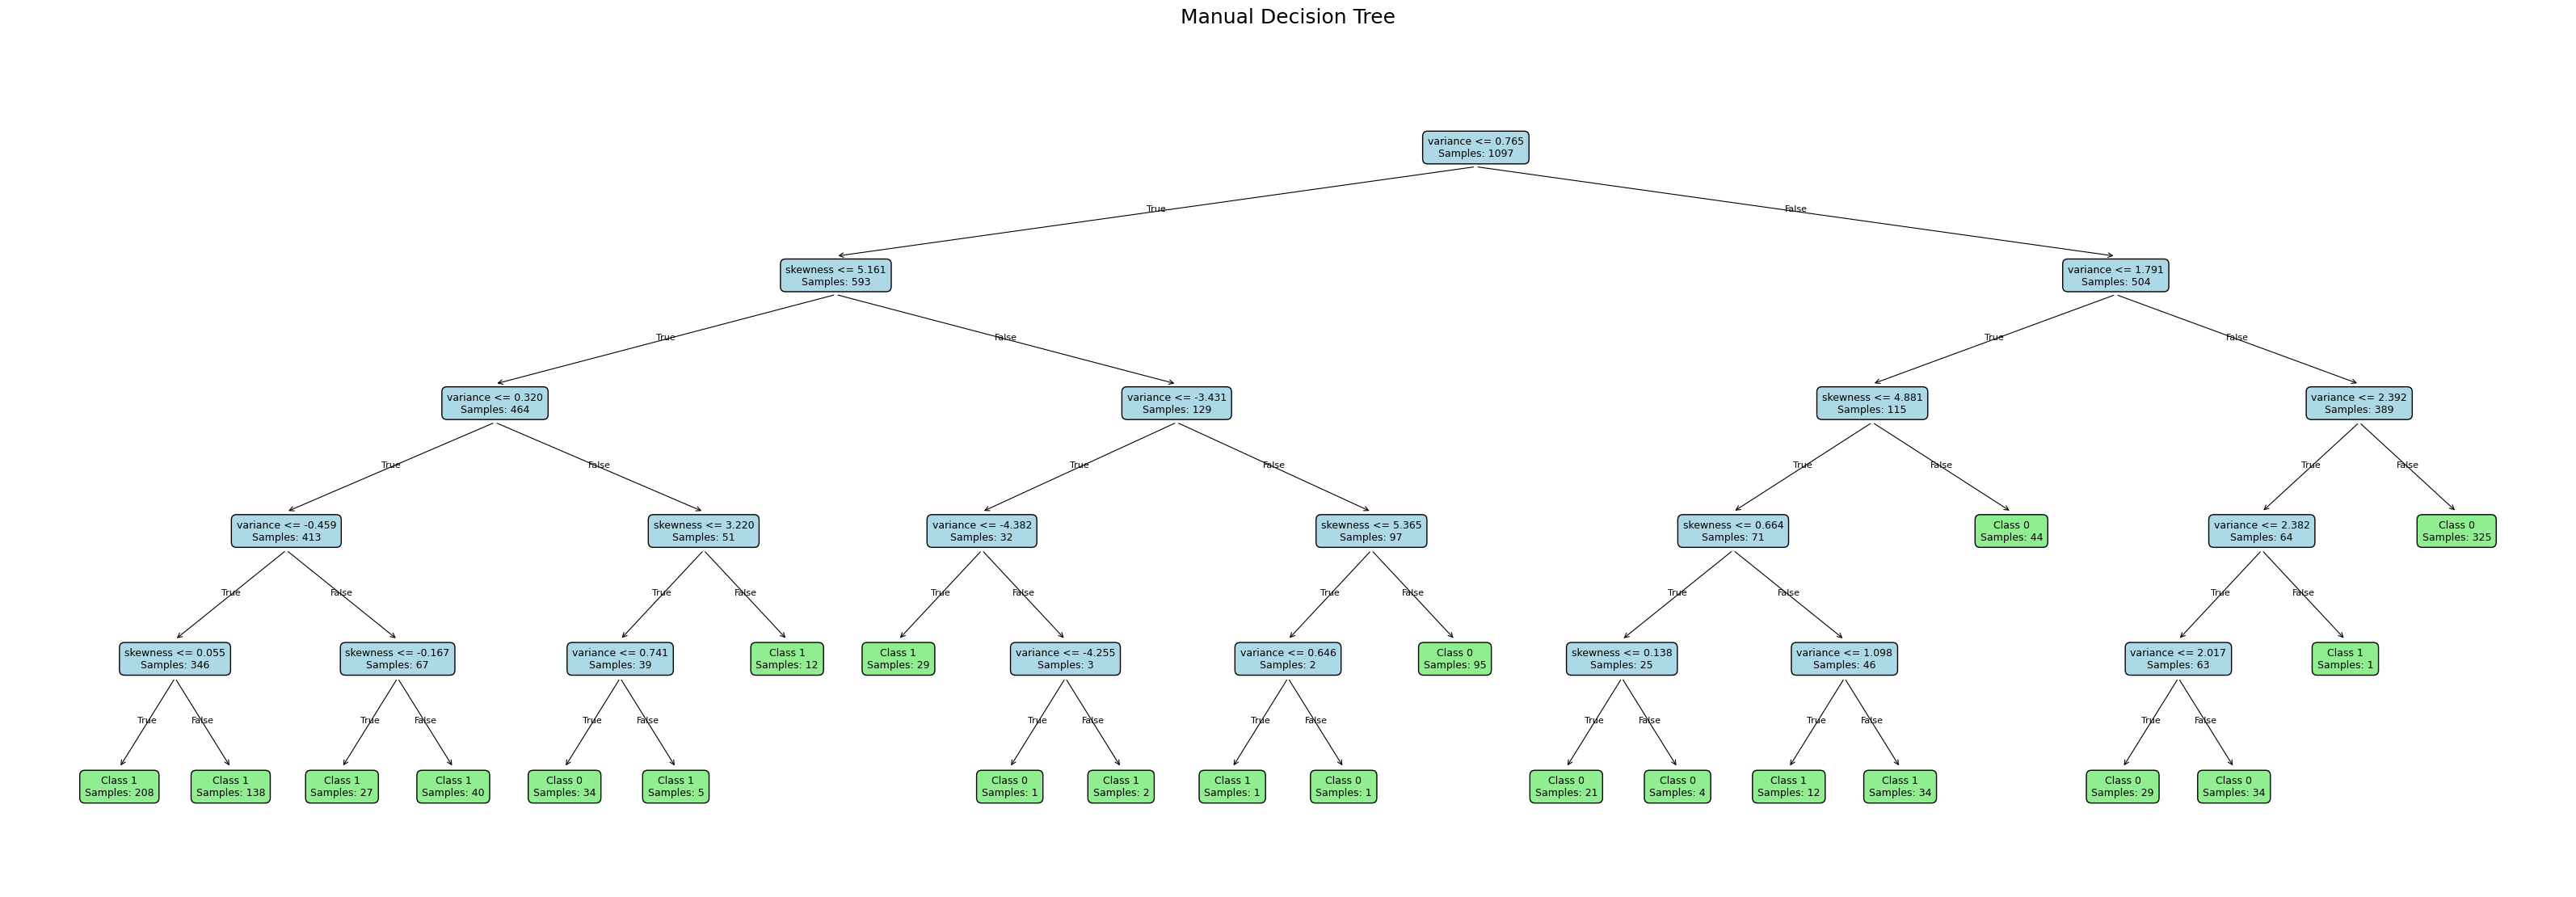

In [14]:
def max_depth_of_tree(node):
    if "feature" not in node:
        return node["depth"]

    return max(
        max_depth_of_tree(node["left"]),
        max_depth_of_tree(node["right"])
    )


def count_leaves(node):
    if "feature" not in node:
        return 1

    return count_leaves(node["left"]) + count_leaves(node["right"])


def plot_manual_tree(node, feature_names):
    positions = {}
    leaf_counter = [0]

    def assign_positions(current):
        if "feature" not in current:
            x_position = leaf_counter[0]
            leaf_counter[0] += 1
        else:
            left_x = assign_positions(current["left"])
            right_x = assign_positions(current["right"])
            x_position = (left_x + right_x) / 2

        positions[id(current)] = (x_position, -current["depth"])
        return x_position

    assign_positions(node)

    leaves = count_leaves(node)
    depth = max_depth_of_tree(node)

    # Increase figure size according to tree width and depth
    fig_width = max(16, leaves * 1.5)
    fig_height = max(8, (depth + 1) * 2.0)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    def draw_nodes(current):
        x, y_position = positions[id(current)]

        if "feature" in current:
            feature = feature_names[current["feature"]]
            threshold = current["threshold"]

            label = (
                f"{feature} <= {threshold:.3f}\n"
                f"Samples: {current['samples']}"
            )
            box_color = "lightblue"
        else:
            label = (
                f"Class {current['prediction']}\n"
                f"Samples: {current['samples']}"
            )
            box_color = "lightgreen"

        ax.text(
            x, y_position, label,
            ha="center",
            va="center",
            fontsize=9,
            bbox=dict(
                boxstyle="round,pad=0.5",
                facecolor=box_color,
                edgecolor="black"
            )
        )

        if "feature" in current:
            for child, edge_label in [
                (current["left"], "True"),
                (current["right"], "False")
            ]:
                child_x, child_y = positions[id(child)]

                ax.annotate(
                    "",
                    xy=(child_x, child_y + 0.15),
                    xytext=(x, y_position - 0.15),
                    arrowprops=dict(
                        arrowstyle="->",
                        color="black",
                        lw=0.8
                    )
                )

                ax.text(
                    (x + child_x) / 2,
                    (y_position + child_y) / 2,
                    edge_label,
                    ha="center",
                    fontsize=8
                )

                draw_nodes(child)

    draw_nodes(node)

    ax.set_title("Manual Decision Tree", fontsize=18, pad=20)
    ax.set_xlim(-1, leaves)
    ax.set_ylim(-depth - 0.8, 0.8)
    ax.axis("off")

    # Avoid tight_layout warning on very wide trees
    fig.subplots_adjust(
        left=0.02, right=0.98,
        top=0.92, bottom=0.05
    )

    plt.show()


plot_manual_tree(manual_tree, feature_names_2d)


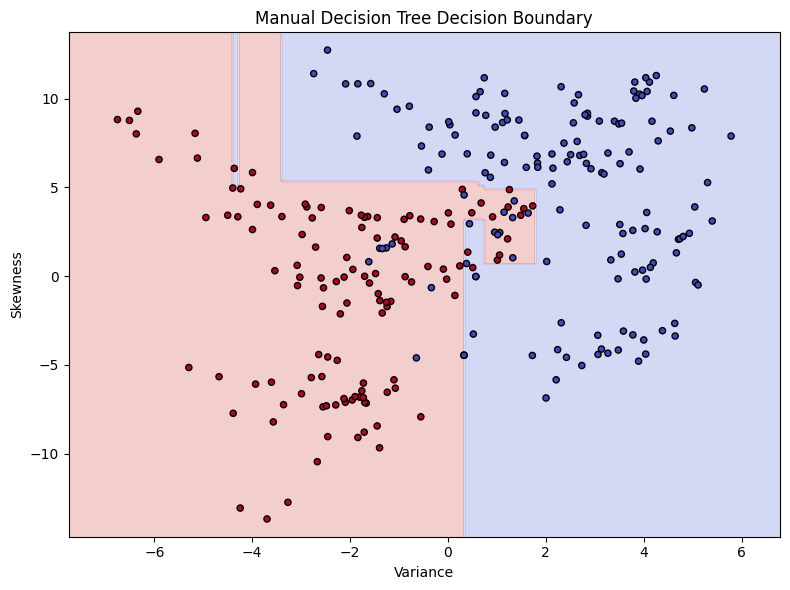

In [15]:
def plot_boundary(model, X_plot, y_plot, title, model_type="manual"):
    x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
    y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    if model_type == "manual":
        Z = predict_tree(model, grid)
    else:
        Z = model.predict(grid)

    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
    plt.scatter(
        X_plot[:, 0], X_plot[:, 1],
        c=y_plot, cmap="coolwarm",
        edgecolors="black", s=20
    )

    plt.xlabel("Variance")
    plt.ylabel("Skewness")
    plt.title(title)
    plt.tight_layout()
    plt.show()


plot_boundary(
    manual_tree,
    X_test_2d,
    y_test,
    "Manual Decision Tree Decision Boundary"
)


Scikit-learn Decision Tree
Test accuracy: 0.9309090909090909

Confusion matrix:
[[137  16]
 [  3 119]]


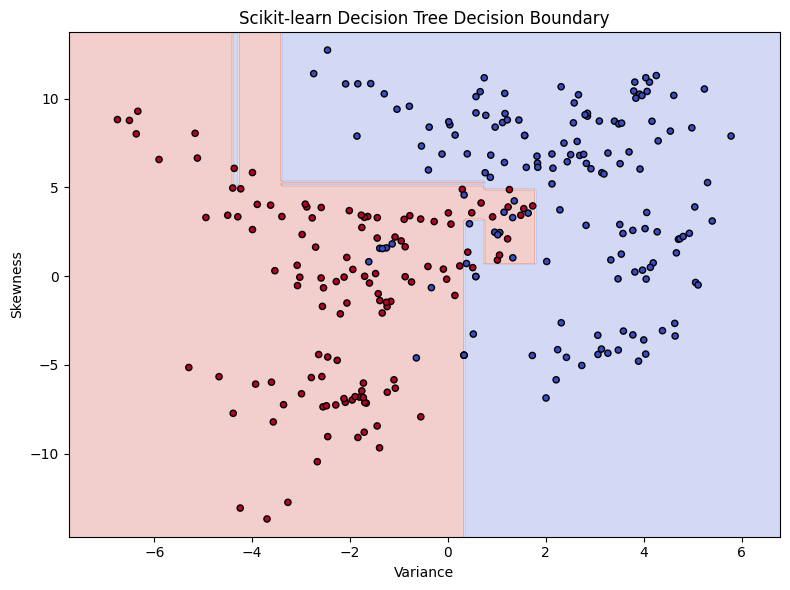

In [16]:
sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

sklearn_tree.fit(X_train_2d, y_train)

sklearn_tree_predictions = sklearn_tree.predict(X_test_2d)

print("Scikit-learn Decision Tree")
print("Test accuracy:", accuracy_score(y_test, sklearn_tree_predictions))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, sklearn_tree_predictions))

plot_boundary(
    sklearn_tree,
    X_test_2d,
    y_test,
    "Scikit-learn Decision Tree Decision Boundary",
    model_type="sklearn"
)


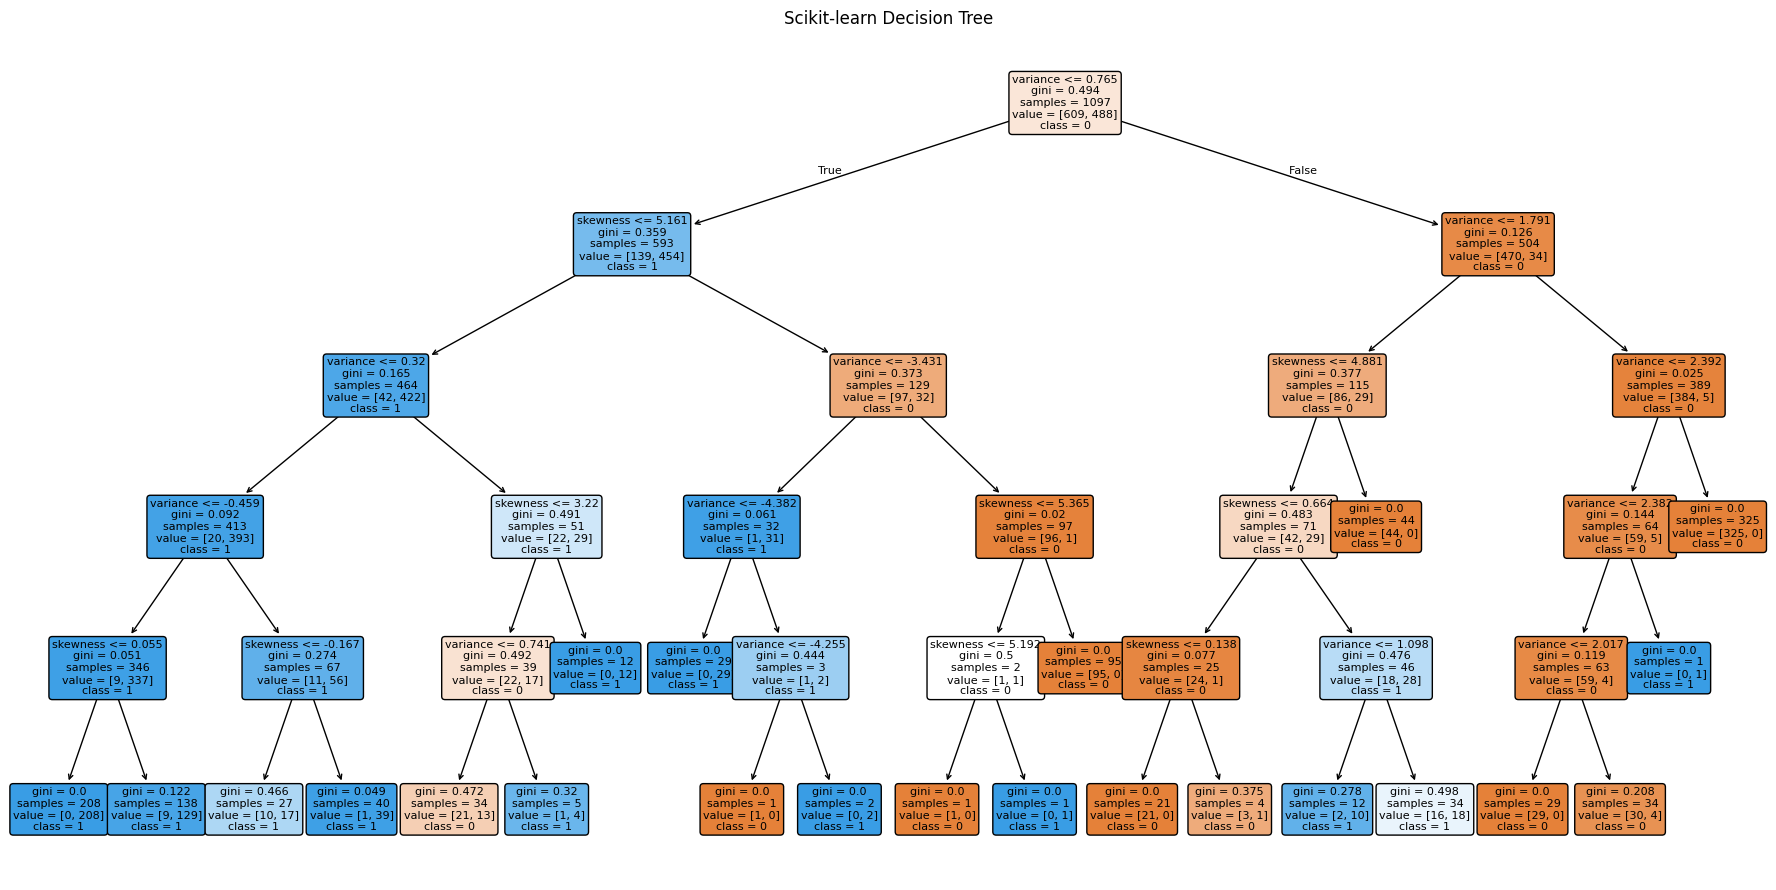

In [17]:
plt.figure(figsize=(18, 9))

plot_tree(
    sklearn_tree,
    feature_names=feature_names_2d,
    class_names=["0", "1"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Scikit-learn Decision Tree")
plt.tight_layout()
plt.show()


In [18]:
tree_results = []

for criterion in ["gini", "entropy"]:
    for depth in [1, 2, 3, 5, 10, None]:

        # Manual tree
        start = time.perf_counter()

        manual_model = build_tree(
            X_train_2d,
            y_train,
            criterion=criterion,
            max_depth=depth
        )

        manual_train_time = time.perf_counter() - start

        start = time.perf_counter()
        manual_pred = predict_tree(manual_model, X_test_2d)
        manual_predict_time = time.perf_counter() - start

        tree_results.append({
            "Implementation": "Manual",
            "Criterion": criterion,
            "Max Depth": str(depth),
            "Accuracy": accuracy_score(y_test, manual_pred),
            "Train Time (s)": manual_train_time,
            "Prediction Time (s)": manual_predict_time
        })

        # Scikit-learn tree
        sklearn_model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            random_state=42
        )

        start = time.perf_counter()
        sklearn_model.fit(X_train_2d, y_train)
        sklearn_train_time = time.perf_counter() - start

        start = time.perf_counter()
        sklearn_pred = sklearn_model.predict(X_test_2d)
        sklearn_predict_time = time.perf_counter() - start

        tree_results.append({
            "Implementation": "Scikit-learn",
            "Criterion": criterion,
            "Max Depth": str(depth),
            "Accuracy": accuracy_score(y_test, sklearn_pred),
            "Train Time (s)": sklearn_train_time,
            "Prediction Time (s)": sklearn_predict_time
        })

tree_results_df = pd.DataFrame(tree_results)

display(
    tree_results_df.sort_values(
        by=["Criterion", "Max Depth", "Implementation"]
    ).reset_index(drop=True)
)


,Implementation,Criterion,Max Depth,Accuracy,Train Time (s),Prediction Time (s)
0,Manual,entropy,1,0.829091,0.243151,0.000234
1,Scikit-learn,entropy,1,0.829091,0.003261,0.000349
2,Manual,entropy,10,0.934545,1.246509,0.002350
3,Scikit-learn,entropy,10,0.930909,0.006032,0.000592
4,Manual,entropy,2,0.876364,0.403772,0.000365
5,Scikit-learn,entropy,2,0.876364,0.003339,0.000369
6,Manual,entropy,3,0.909091,0.616638,0.000531
7,Scikit-learn,entropy,3,0.909091,0.003792,0.000525
8,Manual,entropy,5,0.934545,1.613784,0.000531
9,Scikit-learn,entropy,5,0.934545,0.003947,0.000321


In [19]:
# Fit scaler on training data only
scaler_2d = StandardScaler()

X_train_svm = scaler_2d.fit_transform(X_train_2d)
X_test_svm = scaler_2d.transform(X_test_2d)

# Convert labels from {0, 1} to {-1, +1}
y_train_svm = np.where(y_train == 1, 1, -1)
y_test_svm = np.where(y_test == 1, 1, -1)

print("Training features:", X_train_svm.shape)
print("Testing features:", X_test_svm.shape)
print("Training labels:", np.unique(y_train_svm))
print("Testing labels:", np.unique(y_test_svm))
print("Training feature means:", X_train_svm.mean(axis=0))
print("Training feature standard deviations:", X_train_svm.std(axis=0))


Training features: (1097, 2)
Testing features: (275, 2)
Training labels: [-1  1]
Testing labels: [-1  1]
Training feature means: [-8.72390380e-17 -3.24666861e-16]
Training feature standard deviations: [1. 1.]


In [20]:
class ManualLinearSVM:
    def __init__(self, C=1.0, learning_rate=0.01, iterations=2000):
        self.C = C
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.w = None
        self.b = None
        self.loss_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.w = np.zeros(n_features, dtype=float)
        self.b = 0.0
        self.loss_history = []

        for _ in range(self.iterations):
            margins = y * (X @ self.w + self.b)
            violations = margins < 1

            # Gradient of regularization plus hinge loss
            dw = self.w - self.C * (
                X[violations].T @ y[violations]
            ) / n_samples

            db = -self.C * np.sum(y[violations]) / n_samples

            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

            # Record objective after update
            updated_margins = y * (X @ self.w + self.b)
            hinge_loss = np.maximum(0, 1 - updated_margins)

            loss = (
                0.5 * np.dot(self.w, self.w)
                + self.C * np.mean(hinge_loss)
            )

            self.loss_history.append(loss)

        return self

    def decision_function(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)


In [21]:
manual_svm = ManualLinearSVM(
    C=1.0,
    learning_rate=0.01,
    iterations=2000
)

start = time.perf_counter()
manual_svm.fit(X_train_svm, y_train_svm)
manual_svm_train_time = time.perf_counter() - start

start = time.perf_counter()
manual_svm_predictions = manual_svm.predict(X_test_svm)
manual_svm_predict_time = time.perf_counter() - start

print("Weights:", manual_svm.w)
print("Bias:", manual_svm.b)

print(
    "Test accuracy:",
    accuracy_score(y_test_svm, manual_svm_predictions)
)

print("Training time:", manual_svm_train_time)
print("Prediction time:", manual_svm_predict_time)
print("\nConfusion matrix:")
print(confusion_matrix(y_test_svm, manual_svm_predictions))


Weights: [-0.49766283 -0.25958432]
Bias: -0.2874293527803052
Test accuracy: 0.8654545454545455
Training time: 0.8087650000015856
Prediction time: 0.00011760000052163377

Confusion matrix:
[[145   8]
 [ 29  93]]


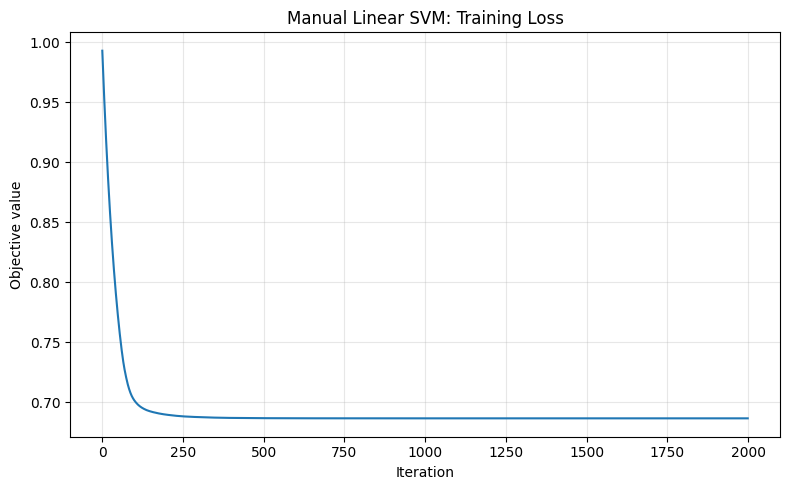

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(manual_svm.loss_history)

plt.xlabel("Iteration")
plt.ylabel("Objective value")
plt.title("Manual Linear SVM: Training Loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


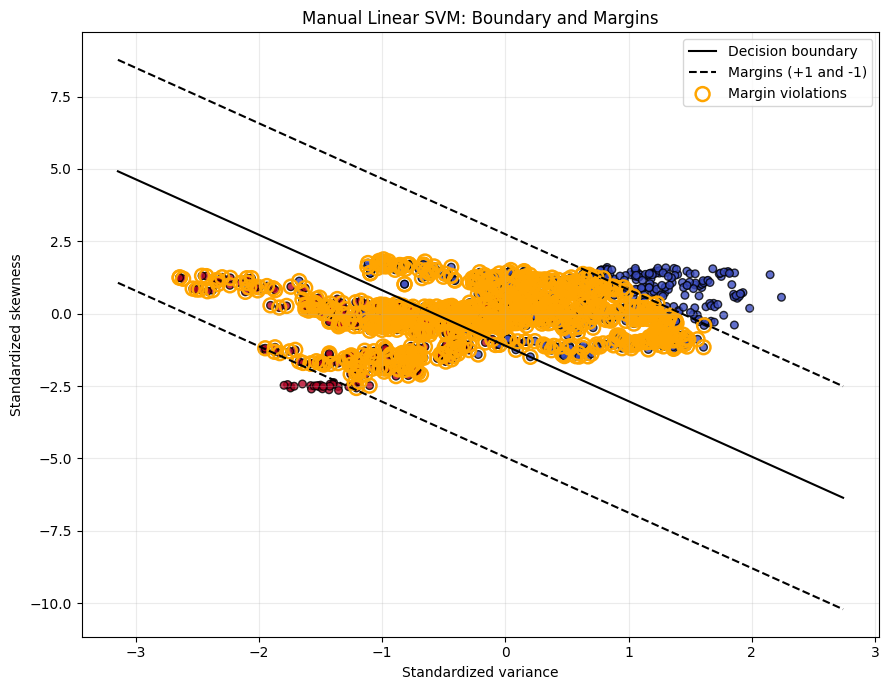

Number of margin-violating training samples: 926


In [23]:
def plot_manual_svm_margins(model, X, y):
    plt.figure(figsize=(9, 7))

    plt.scatter(
        X[:, 0], X[:, 1],
        c=np.where(y == 1, 1, 0),
        cmap="coolwarm",
        edgecolors="black",
        s=30,
        alpha=0.8
    )

    w1, w2 = model.w
    b = model.b

    x_values = np.linspace(
        X[:, 0].min() - 0.5,
        X[:, 0].max() + 0.5,
        300
    )

    if abs(w2) > 1e-10:
        # Decision boundary: w.x + b = 0
        plt.plot(
            x_values, -(w1 * x_values + b) / w2,
            "k-", label="Decision boundary"
        )

        # Margins: w.x + b = +/- 1
        plt.plot(
            x_values, -(w1 * x_values + b - 1) / w2,
            "k--", label="Margins (+1 and -1)"
        )

        plt.plot(
            x_values, -(w1 * x_values + b + 1) / w2,
            "k--"
        )

    # Margin-violating samples have y * f(x) < 1
    margins = y * model.decision_function(X)
    violations = margins < 1

    plt.scatter(
        X[violations, 0],
        X[violations, 1],
        s=100,
        facecolors="none",
        edgecolors="orange",
        linewidths=1.8,
        label="Margin violations"
    )

    plt.xlabel("Standardized variance")
    plt.ylabel("Standardized skewness")
    plt.title("Manual Linear SVM: Boundary and Margins")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    print("Number of margin-violating training samples:",
          np.sum(violations))


plot_manual_svm_margins(
    manual_svm,
    X_train_svm,
    y_train_svm
)


In [24]:
sklearn_svm = SVC(
    kernel="linear",
    C=1.0
)

start = time.perf_counter()
sklearn_svm.fit(X_train_svm, y_train_svm)
sklearn_svm_train_time = time.perf_counter() - start

start = time.perf_counter()
sklearn_svm_predictions = sklearn_svm.predict(X_test_svm)
sklearn_svm_predict_time = time.perf_counter() - start

print("Scikit-learn Linear SVM")
print("Test accuracy:",
      accuracy_score(y_test_svm, sklearn_svm_predictions))

print("Training time:", sklearn_svm_train_time)
print("Prediction time:", sklearn_svm_predict_time)

print("\nConfusion matrix:")
print(confusion_matrix(y_test_svm, sklearn_svm_predictions))


Scikit-learn Linear SVM
Test accuracy: 0.8763636363636363
Training time: 0.21474320000197622
Prediction time: 0.008819700000458397

Confusion matrix:
[[134  19]
 [ 15 107]]


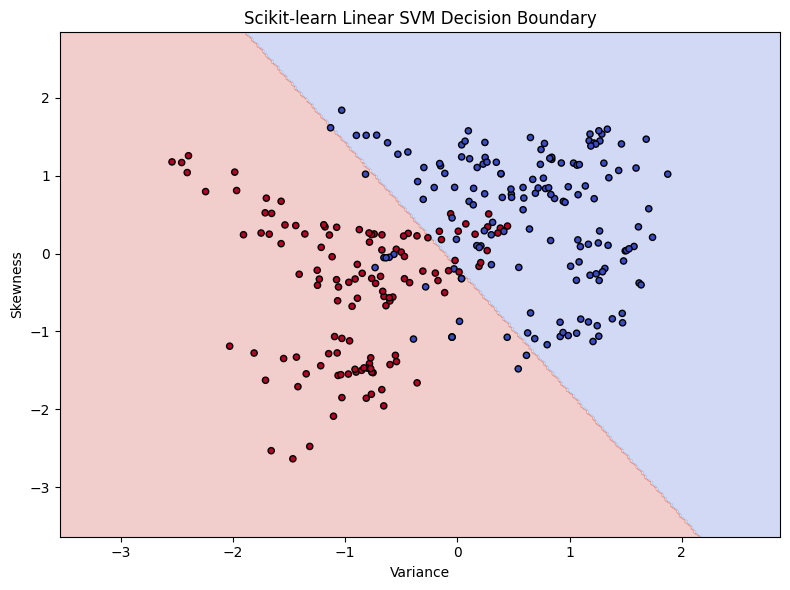

In [25]:

plot_boundary(
    sklearn_svm,
    X_test_svm,
    y_test_svm,
    "Scikit-learn Linear SVM Decision Boundary",
    model_type="sklearn"
)


In [26]:

svm_results = []

for C_value in [0.01, 0.1, 1.0, 10.0]:
    for lr, iterations in [
        (0.01, 1000),
        (0.01, 3000),
        (0.001, 3000)
    ]:
        model = ManualLinearSVM(
            C=C_value,
            learning_rate=lr,
            iterations=iterations
        )

        start = time.perf_counter()
        model.fit(X_train_svm, y_train_svm)
        train_time = time.perf_counter() - start

        predictions = model.predict(X_test_svm)

        svm_results.append({
            "C": C_value,
            "Learning Rate": lr,
            "Iterations": iterations,
            "Accuracy": accuracy_score(
                y_test_svm, predictions
            ),
            "Final Objective": model.loss_history[-1],
            "Training Time (s)": train_time
        })

svm_results_df = pd.DataFrame(svm_results)

display(
    svm_results_df.sort_values(
        "Accuracy", ascending=False
    ).reset_index(drop=True)
)


,C,Learning Rate,Iterations,Accuracy,Final Objective,Training Time (s)
0,10.00,0.001,3000,0.887273,4.038397,0.454574
1,10.00,0.010,1000,0.887273,4.038396,0.168427
2,10.00,0.010,3000,0.887273,4.038396,1.578820
3,1.00,0.001,3000,0.872727,0.687794,1.209894
4,0.10,0.001,3000,0.869091,0.096118,0.399110
5,0.01,0.001,3000,0.869091,0.009961,0.607889
6,1.00,0.010,3000,0.865455,0.686773,0.422210
7,1.00,0.010,1000,0.865455,0.686773,0.139804
8,0.01,0.010,1000,0.712727,0.009953,0.498974
9,0.10,0.010,1000,0.712727,0.095257,0.303381


In [27]:

from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(
    n_samples=600,
    noise=0.20,
    random_state=42
)

X_moons_train, X_moons_test, y_moons_train, y_moons_test = (
    train_test_split(
        X_moons,
        y_moons,
        test_size=0.20,
        random_state=42,
        stratify=y_moons
    )
)

print("Dataset shape:", X_moons.shape)
print("Training set shape:", X_moons_train.shape)
print("Testing set shape:", X_moons_test.shape)
print("Class counts:", np.bincount(y_moons))


Dataset shape: (600, 2)
Training set shape: (480, 2)
Testing set shape: (120, 2)
Class counts: [300 300]


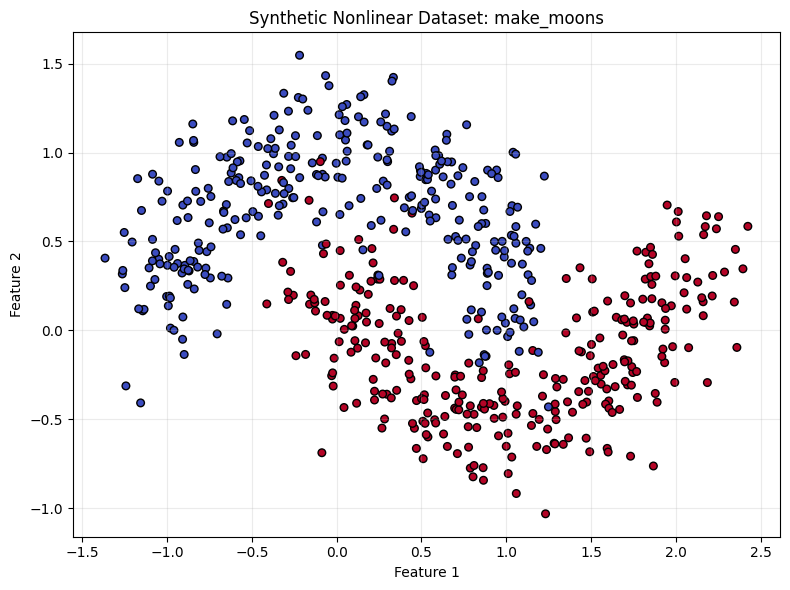

In [28]:

plt.figure(figsize=(8, 6))

plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_moons,
    cmap="coolwarm",
    edgecolors="black",
    s=30
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Nonlinear Dataset: make_moons")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [29]:

moon_scaler = StandardScaler()

X_moons_train_scaled = moon_scaler.fit_transform(X_moons_train)
X_moons_test_scaled = moon_scaler.transform(X_moons_test)

print("Training means:", X_moons_train_scaled.mean(axis=0))
print("Training standard deviations:", X_moons_train_scaled.std(axis=0))


Training means: [2.86113725e-16 4.90348503e-16]
Training standard deviations: [1. 1.]


In [30]:

moon_models = {
    "Linear": SVC(kernel="linear", C=1.0),
    "Polynomial": SVC(kernel="poly", degree=3, C=1.0, gamma="scale"),
    "RBF": SVC(kernel="rbf", C=1.0, gamma="scale")
}

moon_results = []

for name, model in moon_models.items():
    start = time.perf_counter()
    model.fit(X_moons_train_scaled, y_moons_train)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.predict(X_moons_test_scaled)
    predict_time = time.perf_counter() - start

    moon_results.append({
        "Kernel": name,
        "Accuracy": accuracy_score(y_moons_test, predictions),
        "Precision": precision_score(y_moons_test, predictions),
        "Recall": recall_score(y_moons_test, predictions),
        "F1-score": f1_score(y_moons_test, predictions),
        "Training Time (s)": train_time,
        "Prediction Time (s)": predict_time
    })

display(
    pd.DataFrame(moon_results).sort_values(
        "Accuracy", ascending=False
    ).reset_index(drop=True)
)


,Kernel,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,RBF,0.950000,0.921875,0.983333,0.951613,0.007180,0.005307
1,Linear,0.883333,0.870968,0.900000,0.885246,0.139592,0.000802
2,Polynomial,0.883333,0.910714,0.850000,0.879310,0.009199,0.001469


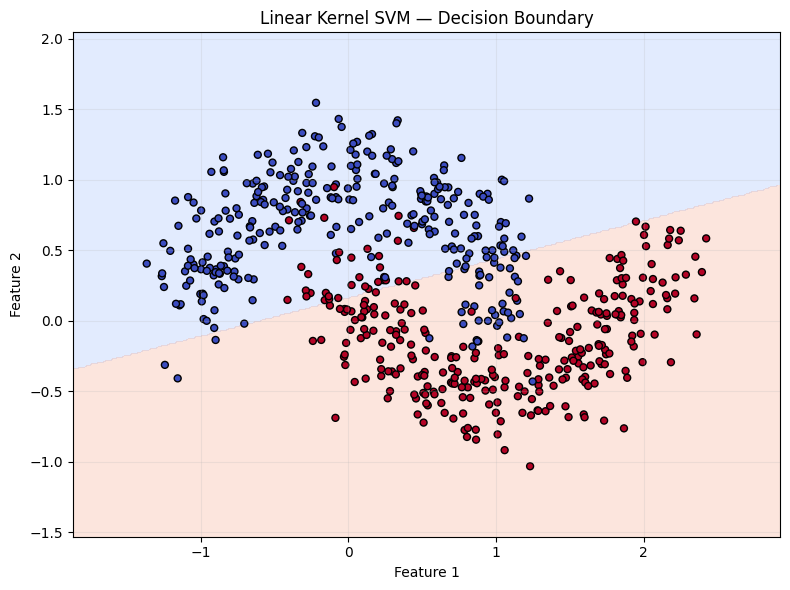

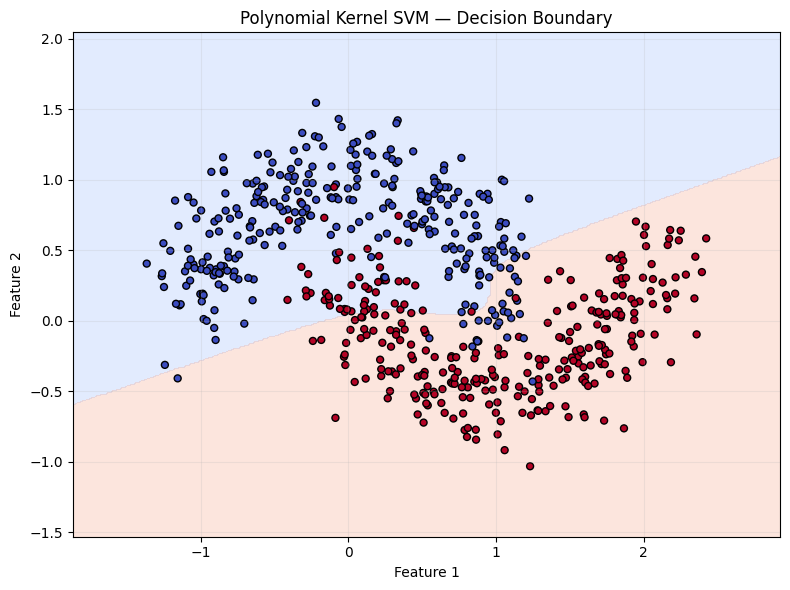

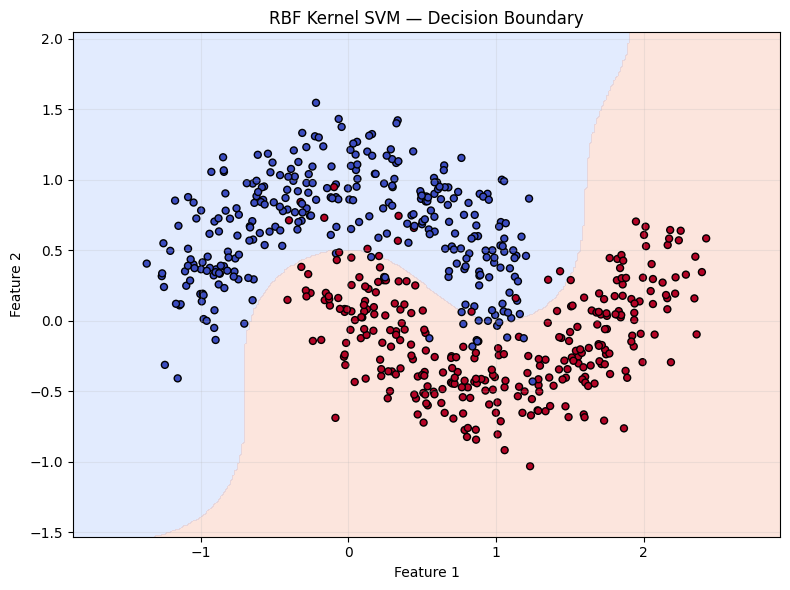

In [31]:

def plot_kernel_boundary(
    model,
    scaler,
    X_original,
    y_original,
    title
):
    x_min = X_original[:, 0].min() - 0.5
    x_max = X_original[:, 0].max() + 0.5
    y_min = X_original[:, 1].min() - 0.5
    y_max = X_original[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid_original = np.c_[xx.ravel(), yy.ravel()]
    grid_scaled = scaler.transform(grid_original)

    Z = model.predict(grid_scaled).reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    plt.contourf(
        xx, yy, Z,
        levels=[-0.5, 0.5, 1.5],
        cmap="coolwarm",
        alpha=0.25
    )

    plt.scatter(
        X_original[:, 0],
        X_original[:, 1],
        c=y_original,
        cmap="coolwarm",
        edgecolors="black",
        s=25
    )

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(title)
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


for name, model in moon_models.items():
    plot_kernel_boundary(
        model,
        moon_scaler,
        X_moons,
        y_moons,
        f"{name} Kernel SVM — Decision Boundary"
    )


In [32]:
kernel_generalization = []

for name, model in moon_models.items():
    train_predictions = model.predict(X_moons_train_scaled)
    test_predictions = model.predict(X_moons_test_scaled)

    kernel_generalization.append({
        "Kernel": name,
        "Training Accuracy": accuracy_score(
            y_moons_train, train_predictions
        ),
        "Testing Accuracy": accuracy_score(
            y_moons_test, test_predictions
        ),
        "Accuracy Gap": (
            accuracy_score(y_moons_train, train_predictions)
            - accuracy_score(y_moons_test, test_predictions)
        )
    })

display(pd.DataFrame(kernel_generalization))


,Kernel,Training Accuracy,Testing Accuracy,Accuracy Gap
0,Linear,0.868750,0.883333,-0.014583
1,Polynomial,0.860417,0.883333,-0.022917
2,RBF,0.952083,0.950000,0.002083


In [33]:
scaler_4d = StandardScaler()

X_train_4d_scaled = scaler_4d.fit_transform(X_train)
X_test_4d_scaled = scaler_4d.transform(X_test)

y_train_svm_4d = np.where(y_train == 1, 1, -1)
y_test_svm_4d = np.where(y_test == 1, 1, -1)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Scaled training means:", X_train_4d_scaled.mean(axis=0))
print("Scaled training standard deviations:", X_train_4d_scaled.std(axis=0))


Training features: (1097, 4)
Testing features: (275, 4)
Scaled training means: [-8.72390380e-17 -3.24666861e-16 -5.25458336e-16  5.76465848e-16]
Scaled training standard deviations: [1. 1. 1. 1.]


In [34]:
final_models = {}
final_results = []


def evaluate_model(name, model, Xtr, ytr, Xte, yte, manual=False):
    start = time.perf_counter()

    if manual == "tree":
        trained_model = build_tree(
            Xtr, ytr,
            criterion="gini",
            max_depth=5
        )
    else:
        trained_model = model.fit(Xtr, ytr)

    training_time = time.perf_counter() - start

    start = time.perf_counter()

    if manual == "tree":
        predictions = predict_tree(trained_model, Xte)
    elif manual == "svm":
        predictions = trained_model.predict(Xte)
        predictions = np.where(predictions == 1, 1, 0)
    else:
        predictions = trained_model.predict(Xte)

    prediction_time = time.perf_counter() - start

    final_models[name] = trained_model

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(yte, predictions),
        "Precision": precision_score(
            yte, predictions, zero_division=0
        ),
        "Recall": recall_score(
            yte, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            yte, predictions, zero_division=0
        ),
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })

    return predictions


# 1. Manual Decision Tree: all four original features
pred_manual_tree_4d = evaluate_model(
    "Manual Decision Tree",
    None,
    X_train, y_train,
    X_test, y_test,
    manual="tree"
)

# 2. Scikit-learn Decision Tree
pred_sklearn_tree_4d = evaluate_model(
    "Scikit-learn Decision Tree",
    DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        random_state=42
    ),
    X_train, y_train,
    X_test, y_test
)

# 3. Manual Linear SVM
manual_svm_4d = ManualLinearSVM(
    C=1.0,
    learning_rate=0.01,
    iterations=3000
)

pred_manual_svm_4d = evaluate_model(
    "Manual Linear SVM",
    manual_svm_4d,
    X_train_4d_scaled, y_train_svm_4d,
    X_test_4d_scaled, y_test,
    manual="svm"
)

# 4. Scikit-learn Linear SVM
pred_sklearn_linear_4d = evaluate_model(
    "Scikit-learn Linear SVM",
    SVC(kernel="linear", C=1.0),
    X_train_4d_scaled, y_train_svm_4d,
    X_test_4d_scaled, y_test_svm_4d
)

# 5. Scikit-learn RBF SVM
pred_sklearn_rbf_4d = evaluate_model(
    "Scikit-learn RBF SVM",
    SVC(kernel="rbf", C=1.0, gamma="scale"),
    X_train_4d_scaled, y_train_svm_4d,
    X_test_4d_scaled, y_test_svm_4d
)

final_results_df = pd.DataFrame(final_results)

display(
    final_results_df.sort_values(
        "F1-score", ascending=False
    ).reset_index(drop=True).round(5)
)


,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Scikit-learn RBF SVM,1.00000,1.00000,1.00000,1.00000,0.00866,0.00363
1,Manual Decision Tree,0.99273,0.98387,1.00000,0.99187,3.57899,0.00097
2,Scikit-learn Decision Tree,0.99273,0.98387,1.00000,0.99187,0.35240,0.00083
3,Scikit-learn Linear SVM,0.97455,0.94574,1.00000,0.97211,0.01263,0.00084
4,Manual Linear SVM,0.88364,0.94118,0.78689,0.85714,0.51608,0.00004


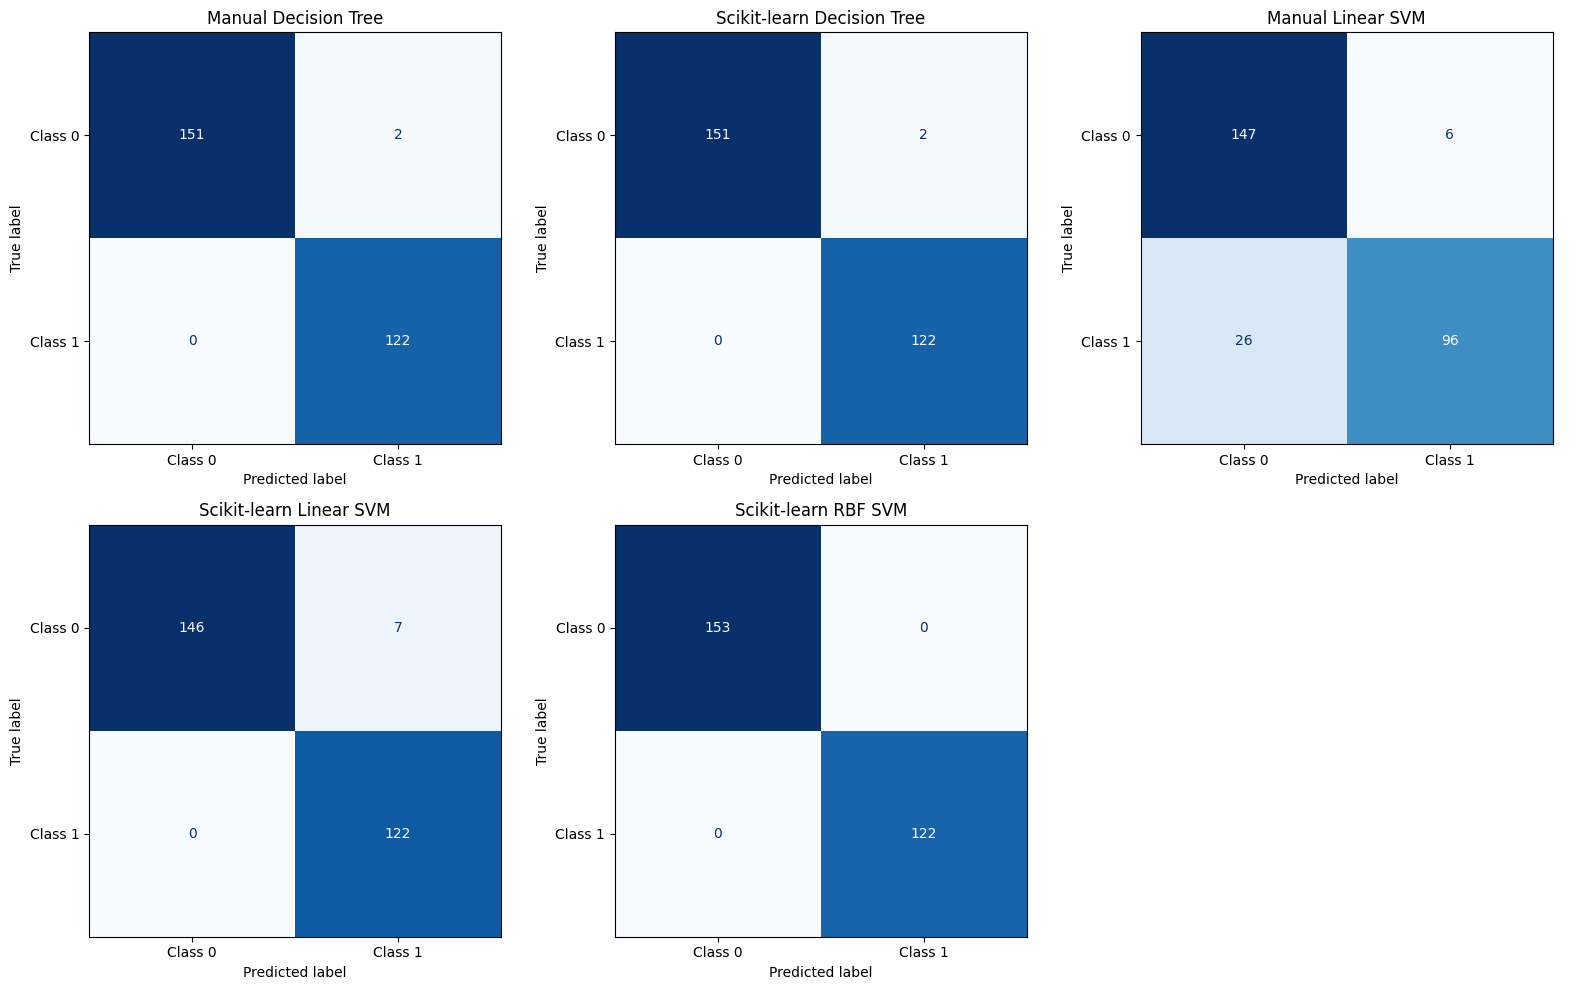

In [35]:
from sklearn.metrics import ConfusionMatrixDisplay

confusion_predictions = {
    "Manual Decision Tree": pred_manual_tree_4d,
    "Scikit-learn Decision Tree": pred_sklearn_tree_4d,
    "Manual Linear SVM": pred_manual_svm_4d,
    "Scikit-learn Linear SVM": np.where(
        pred_sklearn_linear_4d == 1, 1, 0
    ),
    "Scikit-learn RBF SVM": np.where(
        pred_sklearn_rbf_4d == 1, 1, 0
    )
}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, (name, predictions) in zip(
    axes, confusion_predictions.items()
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Class 0", "Class 1"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(name)

# Hide unused sixth subplot
axes[-1].axis("off")

plt.tight_layout()
plt.show()


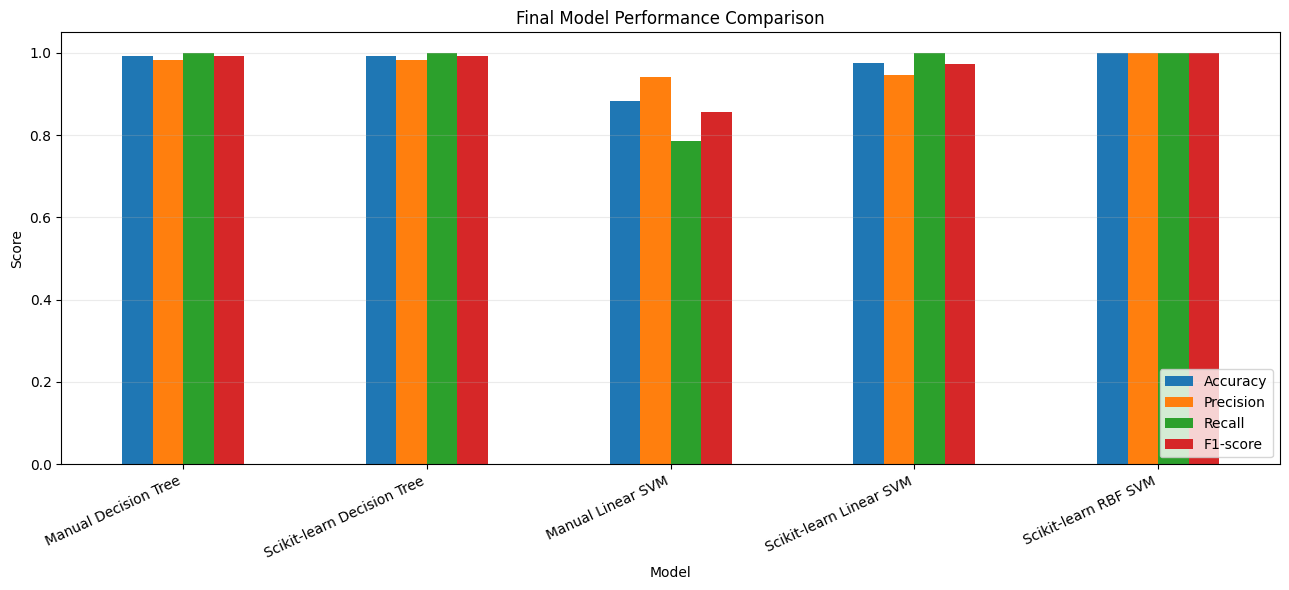

In [36]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

metrics_plot_df = final_results_df.set_index("Model")[metrics_to_plot]

metrics_plot_df.plot(
    kind="bar",
    figsize=(13, 6),
    ylim=(0, 1.05)
)

plt.title("Final Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


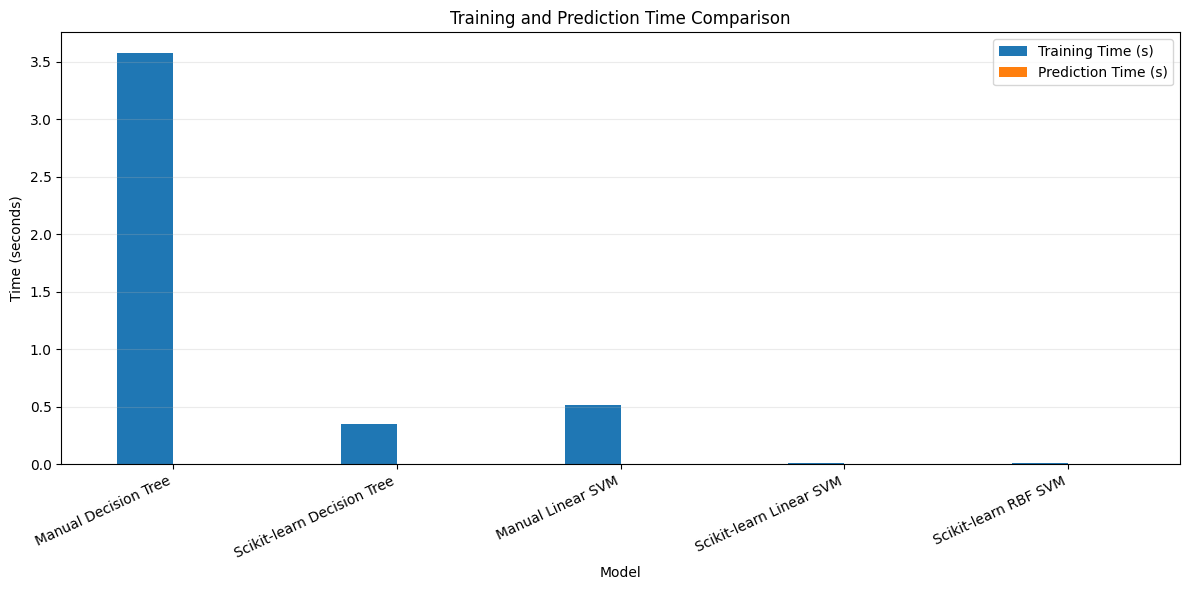

In [37]:
time_plot_df = final_results_df.set_index("Model")[
    ["Training Time (s)", "Prediction Time (s)"]
]

time_plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Training and Prediction Time Comparison")
plt.ylabel("Time (seconds)")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()
